# Model diagnostics
Four figures for inspecting the experiment and presenting its findings. Export each as PNG and PDF. Validation was used for model selection; final-test answers are not loaded.


In [1]:
import os
import json
import hashlib
import textwrap
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file() and (p / "notebooks").is_dir())
os.environ["MPLCONFIGDIR"] = str(ROOT / ".cache/matplotlib")
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, MaxNLocator
from IPython.display import display
get_ipython().run_line_magic("matplotlib", "inline")

OUT = ROOT / "outputs"
FIGURES = OUT / "figures"
FIGURES.mkdir(exist_ok=True)
def read_json(p): return json.loads((ROOT / p).read_text())
def sha256(p):
    with p.open("rb") as f: return hashlib.file_digest(f, "sha256").hexdigest()
report = read_json("outputs/model_comparison.json")
training_report = read_json("outputs/shared_response_training.json")
index = pd.DataFrame(read_json("outputs/question_answer_index.json"))
items = {q["item_id"]: q for q in read_json("data/processed/question_bank.json")["items"]}
selected = next(c for c in report["candidates"] if c["name"] == report["selected"])
original = next(c for c in report["candidates"] if c["name"] == "original_linear_64")
baseline = report["population_baseline"]
source_hashes = {p: sha256(ROOT / p) for p in ["outputs/model_comparison.json", "outputs/shared_response_training.json",
                                            "data/processed/question_bank.json", "outputs/response_scale_priors.json"]}
NAVY, TEAL, MUTED, GREY = "#244260", "#008477", "#AEC0CF", "#747B83"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "axes.titlesize": 13,
                    "axes.labelsize": 11, "axes.spines.top": False, "axes.spines.right": False,
                    "axes.edgecolor": "#CAD1D8", "grid.color": "#E8ECF0", "figure.facecolor": "white",
                    "axes.facecolor": "white", "pdf.fonttype": 42})
exports = []
def save_figure(fig, name):
    for suffix in ["png", "pdf"]:
        path = FIGURES / f"{name}.{suffix}"
        fig.savefig(path, dpi=180, bbox_inches="tight", facecolor="white")
        exports.append({"path": str(path.relative_to(ROOT)), "sha256": sha256(path), "bytes": path.stat().st_size})
    display(fig)
    plt.close(fig)


## 1. Model comparison
Training and validation cover different questions. The panels show their results separately; a high training score alone does not identify the best model.


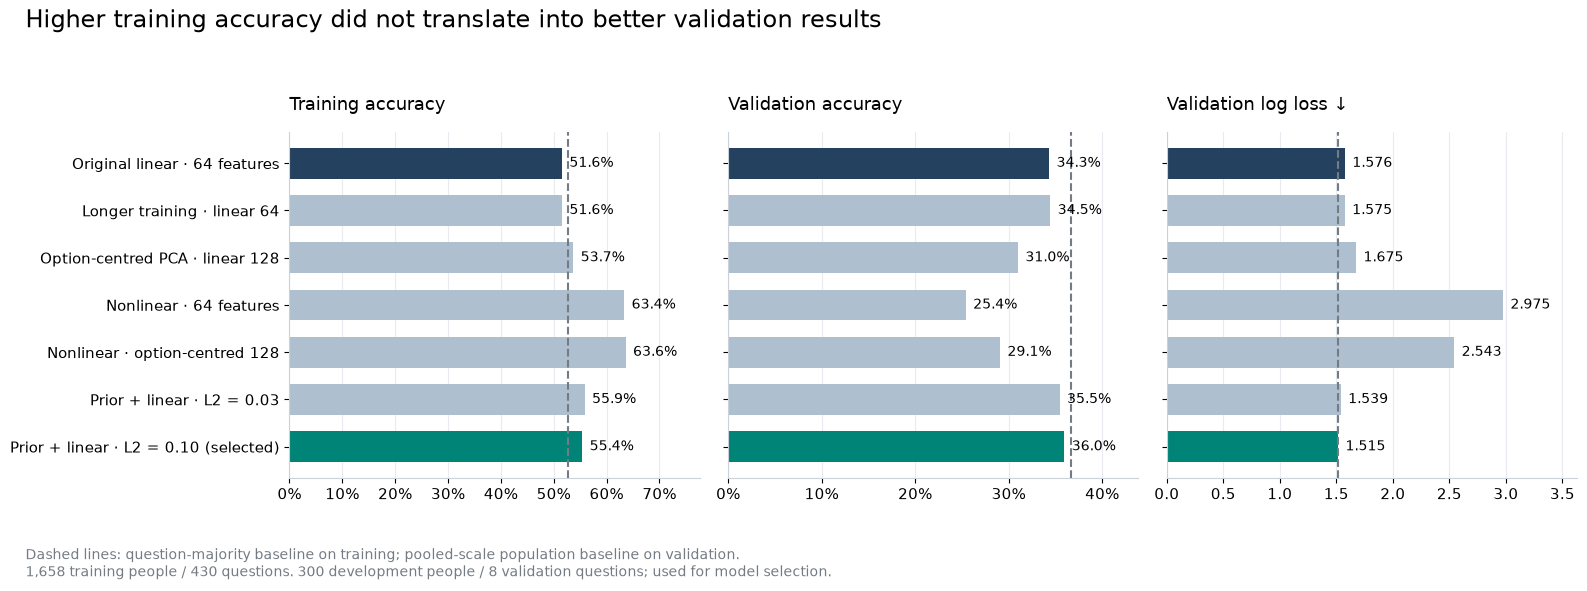

In [2]:
names = {"original_linear_64": "Original linear · 64 features", "longer_linear_64": "Longer training · linear 64",
         "contrast_linear_128": "Option-centred PCA · linear 128", "nonlinear_64": "Nonlinear · 64 features",
         "nonlinear_contrast_128": "Nonlinear · option-centred 128",
         "prior_linear_l2_003": "Prior + linear · L2 = 0.03", "prior_linear_l2_01": "Prior + linear · L2 = 0.10 (selected)"}
models = report["candidates"]
y = np.arange(len(models))
colors = [TEAL if c["name"] == report["selected"] else NAVY if c["name"] == "original_linear_64" else MUTED for c in models]
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)
panels = [("Training accuracy", [c["training"]["accuracy"] for c in models], report["training_modal_accuracy"], True),
          ("Validation accuracy", [c["validation"]["accuracy"] for c in models], baseline["accuracy"], True),
          ("Validation log loss ↓", [c["validation"]["nll"] for c in models], baseline["nll"], False)]
for ax, (title, values, reference, percentage) in zip(axes, panels):
    ax.barh(y, values, color=colors, height=0.65)
    ax.axvline(reference, color=GREY, linestyle="--", linewidth=1.5)
    ax.set_title(title, loc="left", pad=16)
    ax.set_xlim(0, max(values) * 1.22)
    ax.set_axisbelow(True); ax.grid(axis="x")
    if percentage: ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    for row, value in enumerate(values):
        ax.text(value + ax.get_xlim()[1] * 0.018, row, f"{value:.1%}" if percentage else f"{value:.3f}", va="center", fontsize=10)
axes[0].set_yticks(y, [names[c["name"]] for c in models]); axes[0].invert_yaxis()
fig.suptitle("Higher training accuracy did not translate into better validation results", fontsize=17, x=0.02, ha="left")
fig.text(0.02, 0.035, "Dashed lines: question-majority baseline on training; pooled-scale population baseline on validation.\n1,658 training people / 430 questions. 300 development people / 8 validation questions; used for model selection.", fontsize=10, color=GREY)
fig.tight_layout(rect=(0, 0.13, 1, 0.93))
save_figure(fig, "01_model_comparison")


## 2. Validation by question


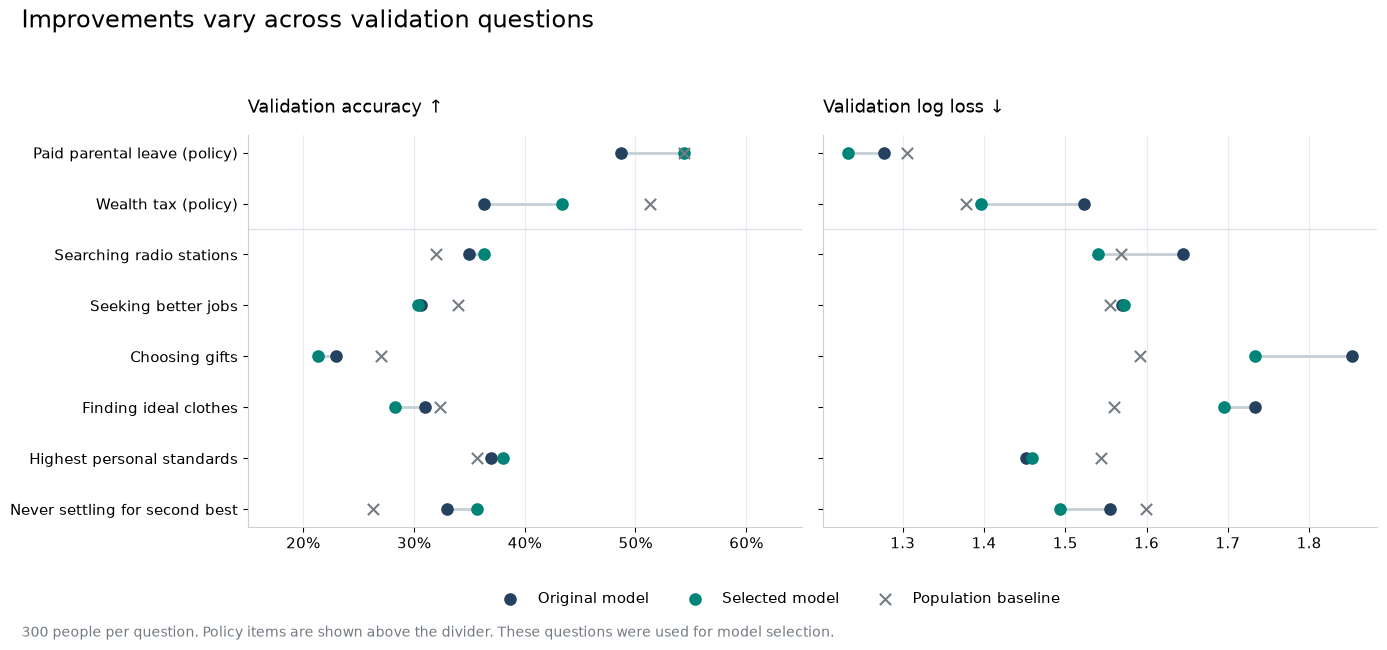

In [3]:
labels = {"QID287_7": "Paid parental leave (policy)", "QID287_10": "Wealth tax (policy)",
          "QID239_1": "Searching radio stations", "QID239_2": "Seeking better jobs", "QID239_3": "Choosing gifts",
          "QID239_4": "Finding ideal clothes", "QID239_5": "Highest personal standards", "QID239_6": "Never settling for second best"}
questions = [q["item_id"] for q in selected["validation"]["per_question"]]
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharey=True)
series = [("Original model", original["validation"]["per_question"], NAVY, "o"),
          ("Selected model", selected["validation"]["per_question"], TEAL, "o"),
          ("Population baseline", baseline["per_question"], GREY, "x")]
for ax, metric, title in zip(axes, ["accuracy", "nll"], ["Validation accuracy ↑", "Validation log loss ↓"]):
    for label, values, color, marker in series:
        lookup = {q["item_id"]: q[metric] for q in values}
        ax.scatter([lookup[q] for q in questions], np.arange(len(questions)), color=color, marker=marker, s=65, label=label, zorder=3)
    for j in range(len(questions)):
        a = original["validation"]["per_question"][j][metric]
        b = selected["validation"]["per_question"][j][metric]
        ax.plot([a, b], [j, j], color="#C5CFD6", linewidth=2, zorder=1)
    ax.axhline(1.5, color="#DCE2E8", linewidth=1)
    ax.set_title(title, loc="left", pad=16); ax.grid(axis="x"); ax.set_axisbelow(True)
    if metric == "accuracy": ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_xlim(0.15, 0.65)
axes[0].set_yticks(np.arange(len(questions)), [labels[q] for q in questions]);axes[0].invert_yaxis()
fig.suptitle("Improvements vary across validation questions", fontsize=17, x=0.02, ha="left")
handles, legend_labels = axes[0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="lower center", ncol=3, bbox_to_anchor=(0.56, 0.04), frameon=False)
fig.text(0.02, 0.015, "300 people per question. Policy items are shown above the divider. These questions were used for model selection.", color=GREY, fontsize=10)
fig.tight_layout(rect=(0, 0.12, 1, 0.93))
save_figure(fig, "02_validation_by_question")


## 3. Human versus predicted answer shares
Model shares average predicted probabilities across the 300 development people, rather than counting their highest-probability answers. Read only the two approved validation files.


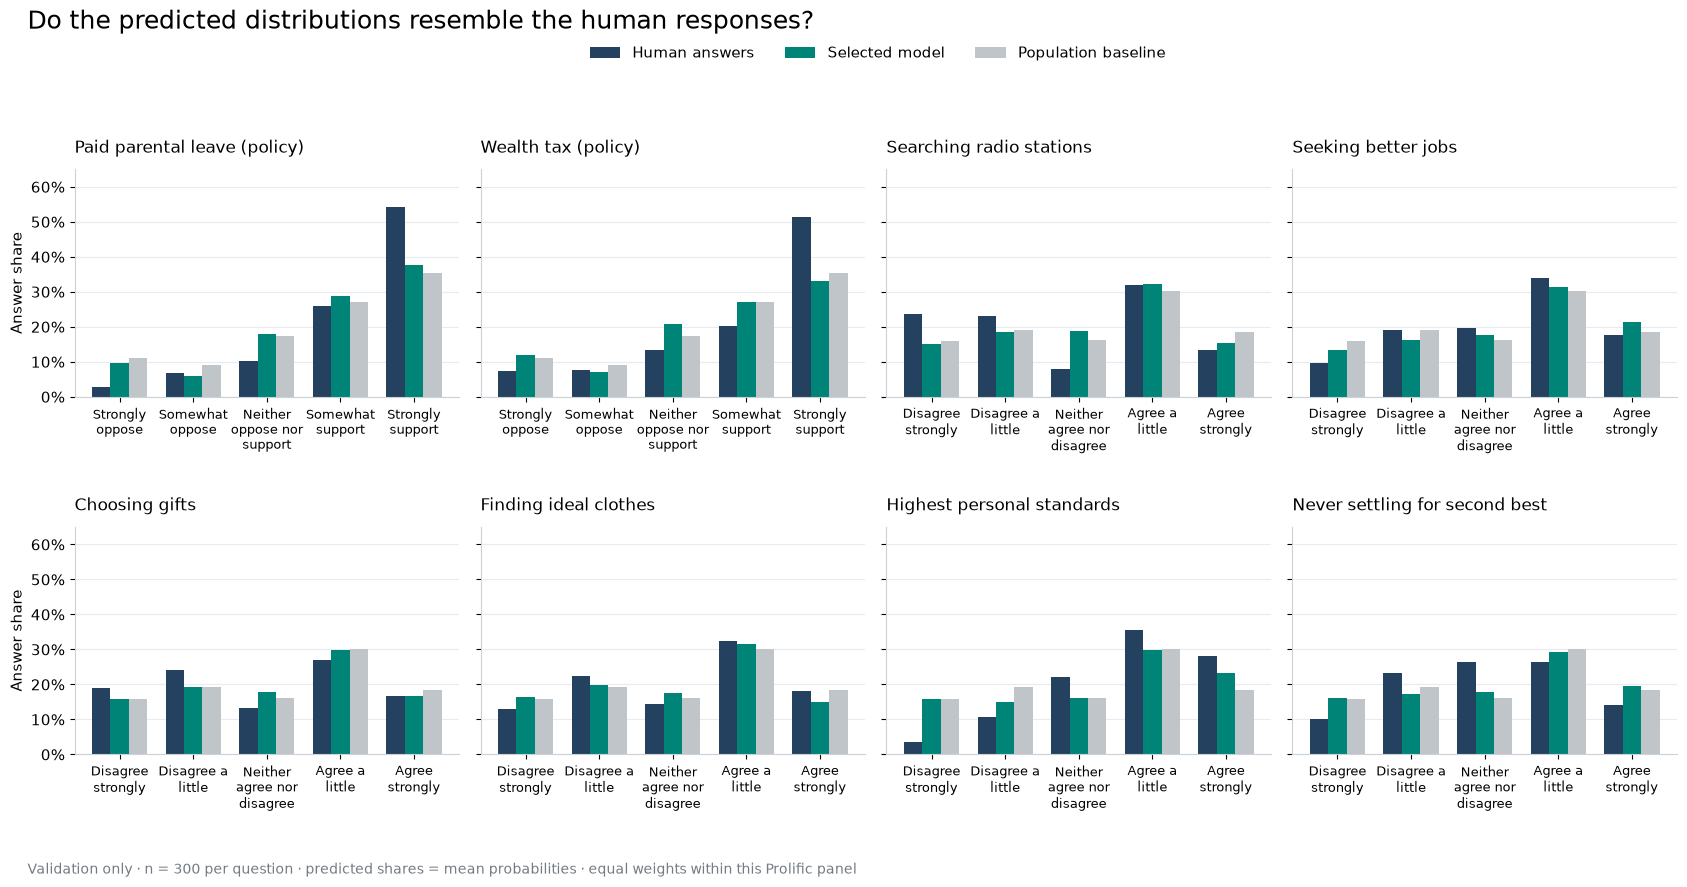

In [4]:
prediction_path = OUT / "development_validation_predictions.npz"
assert sha256(prediction_path) == report["files"][str(prediction_path.relative_to(ROOT))]["sha256"]
source_hashes[str(prediction_path.relative_to(ROOT))] = sha256(prediction_path)
with np.load(prediction_path, allow_pickle=False) as saved:
    probabilities, pids, question_ids, option_counts = [saved[k] for k in ["probabilities", "person_ids", "item_ids", "option_counts"]]
frames = []
for name in ["data/heldout/validation_policy_wave4.parquet", "data/heldout/validation_maximization_wave1_3.parquet"]:
    assert sha256(ROOT / name) == report["input_sha256"][name]
    source_hashes[name] = sha256(ROOT / name)
    frames.append(pd.read_parquet(ROOT / name).set_index("pid"))
validation = pd.concat(frames, axis=1).loc[pids.tolist(), question_ids.tolist()]
assert validation.index.tolist() == pids.tolist() and not validation.isna().any().any()
priors = {tuple(p["option_labels"]): np.array(p["probabilities"]) for p in read_json("outputs/response_scale_priors.json")}
fig, axes = plt.subplots(2, 4, figsize=(17, 9), sharey=True)
share_tables = []
for j, (q, ax) in enumerate(zip(question_ids, axes.flat)):
    n = int(option_counts[j]); options = [o["label"] for o in items[q]["options"]]
    counts = np.bincount(validation[q].to_numpy(dtype=int) - 1, minlength=n)
    human = counts / counts.sum(); predicted = probabilities[:, j, :n].mean(0); population = priors[tuple(options)]
    assert np.isclose(predicted.sum(), 1) and np.isclose(human.sum(), 1)
    tv = float(np.abs(human - predicted).sum() / 2)
    recorded = next(p for p in selected["validation"]["per_question"] if p["item_id"] == q)
    assert np.isclose(tv, recorded["distribution_TV"], atol=1e-6)
    x = np.arange(n); width = 0.25
    ax.bar(x - width, human, width, label="Human answers", color=NAVY)
    ax.bar(x, predicted, width, label="Selected model", color=TEAL)
    ax.bar(x + width, population, width, label="Population baseline", color="#C0C5CA")
    ax.set_title(labels[q], loc="left", fontsize=12, pad=12)
    ax.set_xticks(x, [textwrap.fill(o, width=11) for o in options], fontsize=9)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0));ax.set_ylim(0, 0.65)
    ax.set_axisbelow(True);ax.grid(axis="y");ax.set_ylabel("Answer share" if j % 4 == 0 else "")
    share_tables.append({"item_id": str(q), "options": options, "human_share": human.tolist(),
                         "predicted_share": predicted.tolist(), "population_share": population.tolist(), "distribution_TV": tv})
handles, legend_labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, legend_labels, loc="upper center", ncol=3, bbox_to_anchor=(0.52, 0.955), frameon=False)
fig.suptitle("Do the predicted distributions resemble the human responses?", fontsize=18, x=0.02, ha="left")
fig.text(0.02, 0.02, "Validation only · n = 300 per question · predicted shares = mean probabilities · equal weights within this Prolific panel", color=GREY, fontsize=10)
fig.tight_layout(rect=(0, 0.07, 1, 0.90), h_pad=2.8)
save_figure(fig, "03_validation_answer_distributions")


## 4. Original training curves


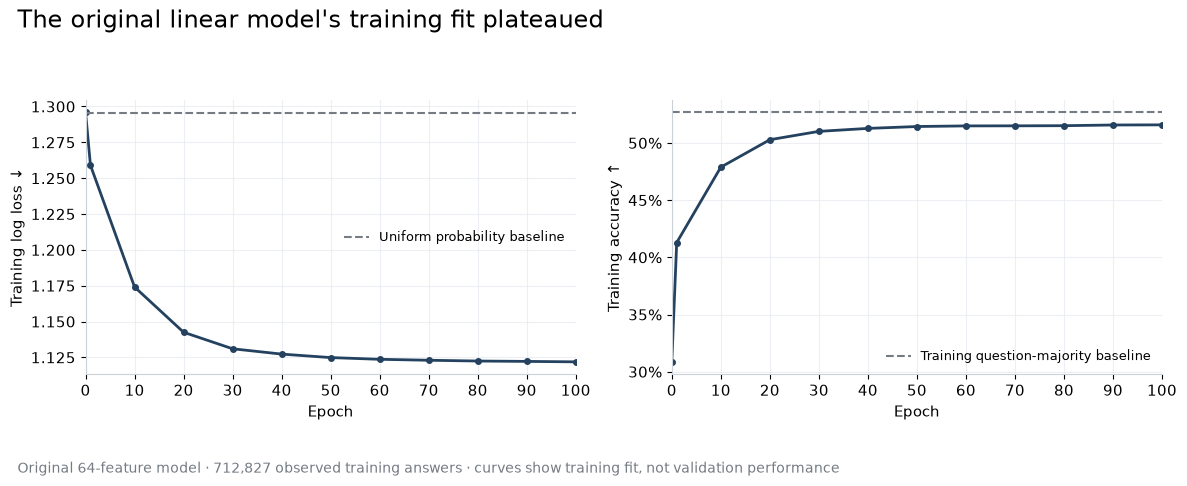

Saved 8 files: four PNG figures and four matching PDFs.


In [5]:
history = pd.DataFrame(training_report["training"]["history"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
axes[0].plot(history.epoch, history.nll, color=NAVY, marker="o", markersize=4, linewidth=2)
axes[0].axhline(training_report["training"]["uniform_baseline"]["nll"], color=GREY, linestyle="--", label="Uniform probability baseline")
axes[0].set_ylabel("Training log loss ↓");axes[0].legend(frameon=False, fontsize=9)
axes[1].plot(history.epoch, history.accuracy, color=NAVY, marker="o", markersize=4, linewidth=2)
axes[1].axhline(report["training_modal_accuracy"], color=GREY, linestyle="--", label="Training question-majority baseline")
axes[1].yaxis.set_major_formatter(PercentFormatter(1, decimals=0));axes[1].set_ylabel("Training accuracy ↑")
axes[1].legend(frameon=False, fontsize=9, loc="lower right")
for ax in axes:
    ax.set_xlabel("Epoch");ax.set_xlim(0, 100);ax.grid(alpha=0.8);ax.xaxis.set_major_locator(MaxNLocator(integer=True))
fig.suptitle("The original linear model's training fit plateaued", fontsize=17, x=0.02, ha="left")
fig.text(0.02, 0.015, "Original 64-feature model · 712,827 observed training answers · curves show training fit, not validation performance", color=GREY, fontsize=10)
fig.tight_layout(rect=(0, 0.09, 1, 0.91))
save_figure(fig, "04_original_training_curves")

for name, digest in source_hashes.items(): assert sha256(ROOT / name) == digest
manifest = {"status": "passed", "source_sha256": source_hashes, "exports": exports,
            "answer_share_data": share_tables, "selected_model": report["selected"],
            "final_test_answers_loaded": False,
            "notes": ["Validation was used for selection; these are not final-test results.",
                      "Population baseline remains slightly better overall on validation accuracy and log loss."]}
(OUT / "plot_manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
print(f"Saved {len(exports)} files: four PNG figures and four matching PDFs.")
